# Xây dựng mô hình hồi quy tuyến tính dự đoán giá xe ô tô đã qua sử dụng

Notebook trình bày quy trình xây dựng và đánh giá mô hình **hồi quy tuyến tính** (Linear Regression) nhằm ước lượng giá xe ô tô đã qua sử dụng tại Việt Nam. Nội dung được triển khai theo trình tự của một bài toán học máy cơ bản: khảo sát dữ liệu, tiền xử lý, phân tích khám phá, xây dựng mô hình, đánh giá kết quả và minh họa khả năng ứng dụng thông qua giao diện Gradio.

## Phát biểu bài toán

Với các thông tin mô tả một xe đã qua sử dụng, bao gồm năm sản xuất, số kilômét đã đi, dung tích động cơ, số chỗ ngồi, xuất xứ, kiểu dáng và hãng xe, mục tiêu của bài toán là **ước lượng giá bán** theo đơn vị triệu VNĐ. Do biến mục tiêu có giá trị liên tục, đây là một **bài toán hồi quy** (regression).

## Các khái niệm chính

| Khái niệm | Diễn giải |
| :--- | :--- |
| Đặc trưng (feature), ký hiệu $X$ | Các biến đầu vào được sử dụng để mô tả xe, chẳng hạn năm sản xuất |
| Biến mục tiêu (target), ký hiệu $y$ | Đại lượng cần ước lượng; trong nghiên cứu này là giá xe |
| Huấn luyện (`fit`) | Quá trình ước lượng các tham số của mô hình từ dữ liệu huấn luyện |
| Dự đoán (`predict`) | Quá trình sử dụng mô hình đã huấn luyện để ước lượng giá trị mục tiêu |
| Hệ số hồi quy $w$ và hệ số chặn $b$ | Các tham số được mô hình ước lượng từ dữ liệu |

Hồi quy tuyến tính biểu diễn giá trị dự đoán dưới dạng tổ hợp tuyến tính của các đặc trưng:

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$$

Trong đó:

- $\hat{y}$ là giá trị do mô hình dự đoán;
- $x_1, x_2, \dots, x_n$ là các đặc trưng đầu vào;
- $w_1, w_2, \dots, w_n$ là các hệ số hồi quy, thể hiện mức thay đổi của giá trị dự đoán theo từng đặc trưng trong điều kiện các đặc trưng còn lại không đổi;
- $b$ là hệ số chặn của mô hình.

Các tham số $w$ và $b$ được ước lượng sao cho hàm mất mát đạt giá trị nhỏ nhất. Trong hồi quy tuyến tính thông thường, tiêu chuẩn tối ưu phổ biến là tổng bình phương sai số, tương ứng với việc tối thiểu hóa sai số bình phương trung bình (MSE).

## Cấu trúc notebook

1. Nhập các thư viện cần thiết
2. Đọc và khảo sát dữ liệu ban đầu
3. Tiền xử lý và làm sạch dữ liệu
4. Phân tích khám phá dữ liệu và xử lý giá trị ngoại lệ
5. Phân chia tập huấn luyện và tập kiểm tra
6. Xây dựng hàm đánh giá mô hình
7. Mô hình cơ sở sử dụng năm sản xuất
8. Minh họa quá trình tối ưu bằng Gradient Descent
9. Mô hình hồi quy tuyến tính đa biến
10. Mô hình hồi quy trên biến đổi logarit của giá
11. Phân tích các hệ số hồi quy
12. So sánh mô hình và phân tích phần dư
13. Minh họa dự đoán trên một quan sát mới
14. Xây dựng giao diện minh họa bằng Gradio
15. Kết luận và định hướng phát triển

## 1. Nhập các thư viện cần thiết

Phần này khai báo các thư viện phục vụ toàn bộ quy trình phân tích. Với `scikit-learn`, quy trình xây dựng mô hình thường gồm bốn bước chính: nhập lớp mô hình, khởi tạo mô hình, huấn luyện bằng phương thức `fit()` và thực hiện dự đoán bằng phương thức `predict()`.

- `pandas` và `numpy`: thao tác dữ liệu dạng bảng và thực hiện các phép tính số học;
- `matplotlib.pyplot`: trực quan hóa dữ liệu và kết quả mô hình;
- `re` và `pathlib.Path`: xử lý chuỗi bằng biểu thức chính quy và quản lý đường dẫn tệp;
- các mô-đun thuộc `sklearn`: phân chia dữ liệu, tiền xử lý đặc trưng, xây dựng mô hình `LinearRegression` và tính toán các chỉ số đánh giá.

In [4]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 30)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.dpi"] = 110

print("Đã import xong thư viện.")

Đã import xong thư viện.


## 2. Đọc và khảo sát dữ liệu ban đầu

Tập dữ liệu được lưu trong tệp `car-price.csv`; mỗi dòng tương ứng với một tin đăng bán xe. Đoạn mã dưới đây tự động tìm tệp trong thư mục `Dataset` bằng cách lần lượt kiểm tra thư mục làm việc hiện tại và các thư mục cha. Cách triển khai này giúp notebook có thể hoạt động ổn định ở nhiều vị trí chạy khác nhau mà không cần khai báo cố định đường dẫn tuyệt đối.

Sau khi nạp dữ liệu, quá trình khảo sát ban đầu tập trung vào các nội dung sau:

- xác định số lượng quan sát và số lượng biến;
- kiểm tra kiểu dữ liệu của từng cột;
- thống kê số lượng giá trị thiếu ở từng biến;
- quan sát một số bản ghi đại diện.

Kết quả khảo sát là cơ sở để lựa chọn phương pháp làm sạch và chuyển đổi dữ liệu ở bước tiếp theo.

In [5]:
dataset_path = None
for base_path in (Path.cwd(), *Path.cwd().parents):
    candidates = (
        base_path / "Dataset" / "car-price.csv",
        base_path / "sources" / "Dataset" / "car-price.csv",
    )
    for candidate in candidates:
        if candidate.exists():
            dataset_path = candidate
            break
    if dataset_path is not None:
        break

if dataset_path is None:
    raise FileNotFoundError("Không tìm thấy car-price.csv trong Dataset hoặc sources/Dataset.")

raw = pd.read_csv(dataset_path)
print(f"Dataset: {dataset_path}")
print(f"Số dòng: {len(raw):,} | Số cột: {len(raw.columns)}")
raw.head(3)

Dataset: d:\TS\PythonEngineer\Project\sources\Dataset\car-price.csv
Số dòng: 15,442 | Số cột: 17


,Name,Condition,Price,Location,Link,Description,Car_code,Năm sản xuất,Tình trạng,Số Km đã đi,Xuất xứ,Kiểu dáng,Động cơ,Màu ngoại thất,Màu nội thất,Số chỗ ngồi,Số cửa
0,Mercedes Benz C class C200 Exclusive - 2021,Xe cũ,1 Tỷ 118 Triệu,Hà Nội,https://bonbanh.com/xe-mercedes_benz-c_class-c...,"*Xe lắp ráp trong nước, màu xanh, máy xăng 2....",Mã: 5807498,2021.0,Xe đã dùng,"38,000 Km",Lắp ráp trong nước,Sedan,Xăng 2.0 L,Xanh,Đen,5 chỗ,4 cửa
1,Nissan Terra E 2.5 AT 2WD - 2019,Xe cũ,646 Triệu,TP HCM,https://bonbanh.com/xe-nissan-terra-e-2.5-at-2...,"*Xe nhập khẩu, màu vàng, máy xăng 2.5 L, số t...",Mã: 5727052,2019.0,Xe đã dùng,"68,000 Km",Nhập khẩu,SUV,Xăng 2.5 L,Vàng,Nâu,7 chỗ,5 cửa
2,Mercedes Benz GLC 300 4Matic - 2021,Xe cũ,1 Tỷ 759 Triệu,Hà Nội,https://bonbanh.com/xe-mercedes_benz-glc-300-4...,"*Xe lắp ráp trong nước, màu đen, máy xăng 2.0...",Mã: 5814403,2021.0,Xe đã dùng,"40,000 Km",Lắp ráp trong nước,SUV,Xăng 2.0 L,Đen,Kem,5 chỗ,5 cửa


In [3]:
print("Kiểu dữ liệu từng cột:")
print(raw.dtypes)
print()
print("Số giá trị thiếu (NaN) từng cột:")
print(raw.isna().sum())

Kiểu dữ liệu từng cột:
Name                  str
Condition             str
Price                 str
Location              str
Link                  str
Description           str
Car_code              str
Năm sản xuất      float64
Tình trạng            str
Số Km đã đi           str
Xuất xứ               str
Kiểu dáng             str
Động cơ               str
Màu ngoại thất        str
Màu nội thất          str
Số chỗ ngồi           str
Số cửa                str
dtype: object

Số giá trị thiếu (NaN) từng cột:
Name                 0
Condition            0
Price                0
Location             0
Link                 0
Description          0
Car_code             0
Năm sản xuất       551
Tình trạng         551
Số Km đã đi       3544
Xuất xứ            551
Kiểu dáng          551
Động cơ            551
Màu ngoại thất     551
Màu nội thất       551
Số chỗ ngồi        551
Số cửa             551
dtype: int64


## 3. Tiền xử lý và làm sạch dữ liệu

Các thuật toán học máy yêu cầu dữ liệu đầu vào có cấu trúc phù hợp, trong khi nhiều biến của tập dữ liệu ban đầu đang được lưu ở dạng chuỗi. Ví dụ, giá xe được biểu diễn dưới dạng `"1 Tỷ 118 Triệu"`, còn quãng đường đã đi được biểu diễn dưới dạng `"38,000 Km"`. Vì vậy, ba hàm chuyển đổi được xây dựng như sau:

- `convert_price(price)`: chuyển chuỗi giá sang giá trị số theo đơn vị triệu VNĐ; ví dụ `"1 Tỷ 118 Triệu"` được chuyển thành `1118`. Biến kết quả là biến mục tiêu của bài toán;
- `extract_number(text)`: trích xuất giá trị số đầu tiên trong chuỗi; ví dụ `"38,000 Km"` thành `38000`, `"5 chỗ"` thành `5` và `"Xăng  2.0 L"` thành `2.0`;
- `extract_brand(name)`: sử dụng từ đầu tiên trong tên xe làm đại diện cho hãng xe; ví dụ `"Toyota Vios 2020"` thành `"Toyota"`. Đây là phương pháp đơn giản hóa và còn hạn chế đối với các hãng có tên gồm nhiều từ, chẳng hạn `"Mercedes Benz"` sẽ được biểu diễn thành `"Mercedes"`.

Sau quá trình chuyển đổi, phân tích chỉ giữ lại bảy đặc trưng và biến mục tiêu. Những quan sát thiếu ít nhất một giá trị trong các biến này được loại bỏ bằng `dropna()`. Các trường như đường dẫn, nội dung mô tả, màu sắc và `Số cửa` không được sử dụng do không thuộc phạm vi mô hình hoặc có dấu hiệu chứa giá trị không hợp lệ.

Các đặc trưng được chia thành hai nhóm:

- **đặc trưng số** (`numeric_cols`): năm sản xuất, số kilômét đã đi, dung tích động cơ và số chỗ ngồi;
- **đặc trưng phân loại** (`categorical_cols`): xuất xứ, kiểu dáng và hãng xe.

In [6]:
def convert_price(price):
    '''Đổi chuỗi giá tiếng Việt thành số triệu VNĐ. Ví dụ: '1 Tỷ 118 Triệu' -> 1118.'''
    if pd.isna(price):
        return np.nan
    price = str(price).strip()
    ty = re.search(r"([\d.,]+)\s*T[yỷ]", price, re.IGNORECASE)
    trieu = re.search(r"([\d.,]+)\s*Tri[eệ]u", price, re.IGNORECASE)
    ty_value = float(ty.group(1).replace(",", ".")) if ty else 0
    trieu_value = float(trieu.group(1).replace(",", ".")) if trieu else 0
    return ty_value * 1000 + trieu_value


def extract_number(text):
    '''Tách số đầu tiên trong một chuỗi, bỏ dấu phẩy phân nghìn.
    Ví dụ: '38,000 Km' -> 38000.0'''
    if pd.isna(text):
        return np.nan
    cleaned = str(text).strip().replace(",", "")
    match = re.search(r"(-?\d+(?:\.\d+)?)", cleaned)
    return float(match.group(1)) if match else np.nan


def extract_brand(name):
    '''Lấy từ đầu tiên của tên xe làm hãng xe gần đúng.
    Ví dụ: 'Toyota Vios 2020' -> 'Toyota'.'''
    if pd.isna(name):
        return np.nan
    first_word = str(name).strip().split(" ")[0]
    return first_word if first_word else np.nan


df = raw.copy()
df["Price_Million"] = df["Price"].apply(convert_price)
df["So_km"] = df["Số Km đã đi"].apply(extract_number)
df["Dung_tich_dong_co"] = df["Động cơ"].apply(extract_number)
df["So_cho_ngoi"] = df["Số chỗ ngồi"].apply(extract_number)
df["Hang_xe"] = df["Name"].apply(extract_brand)

numeric_cols = ["Năm sản xuất", "So_km", "Dung_tich_dong_co", "So_cho_ngoi"]
categorical_cols = ["Xuất xứ", "Kiểu dáng", "Hang_xe"]
target_col = "Price_Million"

feature_cols = numeric_cols + categorical_cols
keep_cols = feature_cols + [target_col]

df_model = df[keep_cols].dropna().reset_index(drop=True)
print(f"Số dòng trước khi làm sạch: {len(df):,}")
print(f"Số dòng sau khi bỏ giá trị thiếu: {len(df_model):,}")
df_model.head()

Số dòng trước khi làm sạch: 15,442
Số dòng sau khi bỏ giá trị thiếu: 11,798


,Năm sản xuất,So_km,Dung_tich_dong_co,So_cho_ngoi,Xuất xứ,Kiểu dáng,Hang_xe,Price_Million
0,2021.0,38000.0,2.0,5.0,Lắp ráp trong nước,Sedan,Mercedes,1118.0
1,2019.0,68000.0,2.5,7.0,Nhập khẩu,SUV,Nissan,646.0
2,2021.0,40000.0,2.0,5.0,Lắp ráp trong nước,SUV,Mercedes,1759.0
3,2016.0,80000.0,2.4,7.0,Lắp ráp trong nước,SUV,Hyundai,664.0
4,2022.0,32000.0,2.2,8.0,Lắp ráp trong nước,Van/Minivan,Kia,1099.0


## 4. Phân tích khám phá dữ liệu và xử lý giá trị ngoại lệ

Phân tích khám phá dữ liệu (Exploratory Data Analysis — EDA) được thực hiện nhằm nhận diện đặc điểm phân phối, xu hướng quan hệ giữa các biến và những quan sát có khả năng ảnh hưởng mạnh đến mô hình. Ba biểu đồ được sử dụng gồm:

- **Biểu đồ tần suất (histogram) của giá xe:** thể hiện hình dạng phân phối của biến mục tiêu. Nếu phần lớn quan sát tập trung ở vùng giá thấp hoặc trung bình trong khi một số ít quan sát có giá rất cao, phân phối được xem là lệch phải;
- **Biểu đồ phân tán giữa năm sản xuất và giá xe:** hỗ trợ đánh giá xu hướng tuyến tính giữa tuổi xe và giá;
- **Biểu đồ phân tán giữa số kilômét đã đi và giá xe:** hỗ trợ khảo sát mối liên hệ giữa mức độ sử dụng và giá bán.

Ngoài trực quan hóa, hệ số tương quan Pearson được tính bằng `corr()`. Hệ số nằm trong khoảng từ $-1$ đến $1$; dấu của hệ số biểu thị chiều quan hệ tuyến tính, còn trị tuyệt đối càng lớn cho thấy mức độ liên hệ tuyến tính càng rõ. Tuy nhiên, tương quan không đồng nghĩa với quan hệ nhân quả.

Hồi quy tuyến tính sử dụng sai số bình phương nên tương đối nhạy cảm với các quan sát ngoại lệ. Một số xe có giá đặc biệt cao hoặc dữ liệu nhập sai có thể tạo ảnh hưởng lớn đến các hệ số ước lượng. Trong phạm vi notebook, phương pháp cắt theo phân vị được áp dụng: loại bỏ 1% quan sát có giá thấp nhất và 1% quan sát có giá cao nhất. Đây là một lựa chọn thực nghiệm nhằm giảm ảnh hưởng của các giá trị cực đoan; ngưỡng này cần được đánh giá lại khi triển khai trên dữ liệu hoặc mục tiêu nghiệp vụ khác.

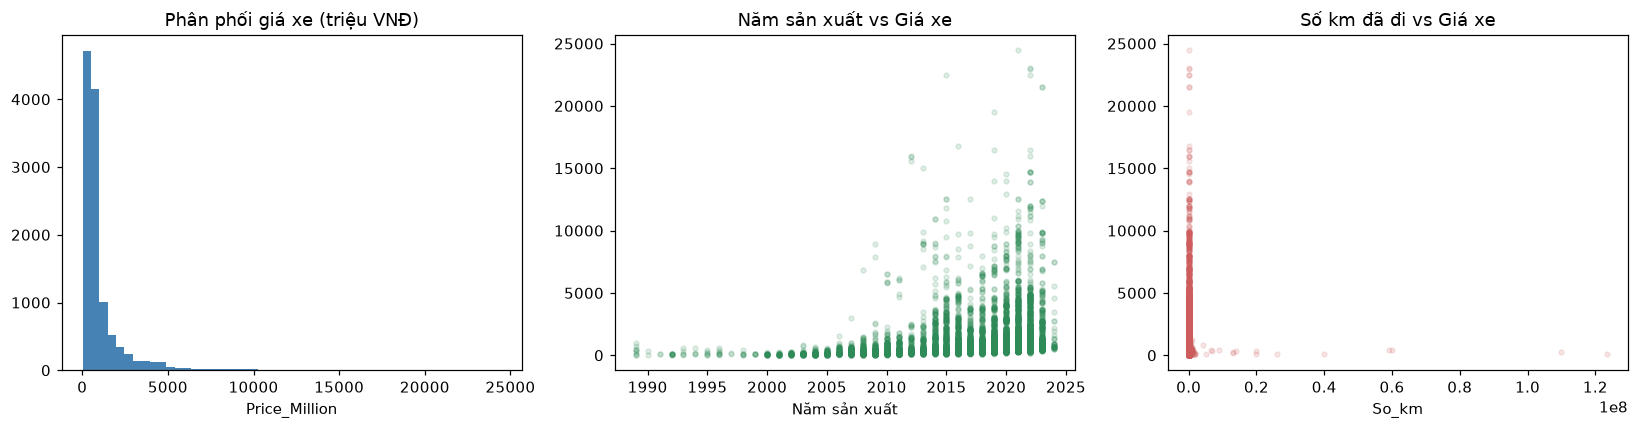

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df_model["Price_Million"], bins=50, color="steelblue")
axes[0].set_title("Phân phối giá xe (triệu VNĐ)")
axes[0].set_xlabel("Price_Million")

axes[1].scatter(df_model["Năm sản xuất"], df_model["Price_Million"], alpha=0.15, s=10, color="seagreen")
axes[1].set_title("Năm sản xuất vs Giá xe")
axes[1].set_xlabel("Năm sản xuất")

axes[2].scatter(df_model["So_km"], df_model["Price_Million"], alpha=0.15, s=10, color="indianred")
axes[2].set_title("Số km đã đi vs Giá xe")
axes[2].set_xlabel("So_km")

fig.tight_layout()
plt.show()

In [8]:
print("Tương quan (correlation) với Price_Million:")
print(df_model[numeric_cols + [target_col]].corr()[target_col].sort_values(ascending=False))

Tương quan (correlation) với Price_Million:
Price_Million        1.000000
Dung_tich_dong_co    0.566506
Năm sản xuất         0.218662
So_km               -0.017580
So_cho_ngoi         -0.079734
Name: Price_Million, dtype: float64


In [9]:
q_low = df_model["Price_Million"].quantile(0.01)
q_high = df_model["Price_Million"].quantile(0.99)

print(f"Ngưỡng lọc outlier: {q_low:,.1f} triệu VNĐ đến {q_high:,.1f} triệu VNĐ")

before = len(df_model)
df_model = df_model[(df_model["Price_Million"] >= q_low) & (df_model["Price_Million"] <= q_high)].reset_index(drop=True)
after = len(df_model)

print(f"Số dòng trước khi lọc outlier: {before:,}")
print(f"Số dòng sau khi lọc outlier: {after:,} (đã bỏ {before - after:,} dòng)")

Ngưỡng lọc outlier: 69.0 triệu VNĐ đến 8,601.5 triệu VNĐ
Số dòng trước khi lọc outlier: 11,798
Số dòng sau khi lọc outlier: 11,563 (đã bỏ 235 dòng)


## 5. Phân chia tập huấn luyện và tập kiểm tra

Đánh giá mô hình trên chính dữ liệu đã sử dụng để huấn luyện thường tạo ra kết quả lạc quan và không phản ánh đầy đủ khả năng khái quát hóa đối với dữ liệu mới. Vì vậy, tập dữ liệu được phân chia thành hai phần:

- **tập huấn luyện (Train, 80%)**: được sử dụng để ước lượng các tham số thông qua phương thức `fit()`;
- **tập kiểm tra (Test, 20%)**: được giữ độc lập khỏi quá trình huấn luyện và chỉ sử dụng để tạo dự đoán bằng `predict()` và tính toán các chỉ số đánh giá.

Mọi thao tác học tham số, bao gồm chuẩn hóa dữ liệu và mã hóa biến phân loại, phải chỉ dựa trên tập huấn luyện. Việc sử dụng thông tin từ tập kiểm tra trong quá trình xây dựng mô hình sẽ gây ra **rò rỉ dữ liệu** (data leakage), làm suy giảm độ tin cậy của kết quả đánh giá.

Tham số `random_state=42` được thiết lập để bảo đảm phép chia dữ liệu có thể tái lập giữa các lần chạy notebook.

In [10]:
X = df_model[feature_cols]
y = df_model[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Số dòng Train: {len(X_train):,}")
print(f"Số dòng Test : {len(X_test):,}")

Số dòng Train: 9,250
Số dòng Test : 2,313


## 6. Xây dựng hàm đánh giá mô hình

Hiệu năng dự báo được xác định bằng cách so sánh giá trị thực tế với giá trị dự đoán trên tập kiểm tra. Ba chỉ số được sử dụng gồm:

- **MAE (Mean Absolute Error — sai số tuyệt đối trung bình):** biểu thị độ lệch tuyệt đối trung bình giữa giá thực tế và giá dự đoán. Chẳng hạn, MAE bằng 250 cho thấy dự đoán sai lệch trung bình khoảng 250 triệu VNĐ. Giá trị càng nhỏ thể hiện sai số trung bình càng thấp;
- **RMSE (Root Mean Squared Error — căn bậc hai của sai số bình phương trung bình):** có cùng đơn vị với biến mục tiêu nhưng nhạy hơn với các sai số lớn do thành phần sai số được bình phương. RMSE luôn không nhỏ hơn MAE; giá trị càng thấp càng tốt;
- **$R^2$ (hệ số xác định):** phản ánh tỷ lệ biến thiên của biến mục tiêu được mô hình giải thích trên tập đánh giá. $R^2=1$ tương ứng với dự đoán hoàn hảo; $R^2=0$ cho thấy mô hình có mức độ phù hợp tương đương dự đoán hằng số bằng trung bình của tập đánh giá; giá trị âm cho thấy mô hình kém hơn mốc so sánh này.

Hàm `evaluate()` được định nghĩa để áp dụng thống nhất ba chỉ số cho tất cả mô hình và lưu kết quả phục vụ bước đối chiếu.

In [11]:
def evaluate(name, y_true, y_pred):
    '''Tính MAE, RMSE, R2 và in kết quả. Trả về dict để dùng làm bảng so sánh.'''
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"[{name}] MAE = {mae:,.2f} | RMSE = {rmse:,.2f} | R2 = {r2:.4f}")
    return {"Mô hình": name, "MAE": mae, "RMSE": rmse, "R2": r2}


results = []
predictions = {}

## 7. Mô hình cơ sở sử dụng năm sản xuất

Mô hình đầu tiên chỉ sử dụng biến `Năm sản xuất` để ước lượng giá xe. Đây là mô hình hồi quy tuyến tính đơn với phương trình:

$$\widehat{\text{Giá}} = w \times \text{Năm sản xuất} + b$$

Trong đó:

- $w$ là hệ số góc, biểu thị mức thay đổi trung bình của giá dự đoán khi năm sản xuất tăng một đơn vị;
- $b$ là hệ số chặn, tức giá trị dự đoán khi biến đầu vào bằng 0. Trong ngữ cảnh này, $b$ chủ yếu có ý nghĩa toán học và không nên diễn giải độc lập vì năm sản xuất bằng 0 nằm ngoài miền dữ liệu quan sát.

Mô hình này được sử dụng làm **mô hình cơ sở** (baseline). Các mô hình phức tạp hơn chỉ được xem là có giá trị bổ sung khi cải thiện hiệu năng trên cùng tập kiểm tra.

In [12]:
baseline_model = LinearRegression()
baseline_model.fit(X_train[["Năm sản xuất"]], y_train)

y_pred_baseline = baseline_model.predict(X_test[["Năm sản xuất"]])

slope = baseline_model.coef_[0]
intercept = baseline_model.intercept_
dau = "+" if intercept >= 0 else "-"
print(f"Phương trình: Price_Million = {slope:,.4f} × Năm_sản_xuất {dau} {abs(intercept):,.4f}")

res_baseline = evaluate("1. Baseline (1 biến)", y_test, y_pred_baseline)
results.append(res_baseline)
predictions["1. Baseline (1 biến)"] = y_pred_baseline

Phương trình: Price_Million = 60.1932 × Năm_sản_xuất - 120,474.6050
[1. Baseline (1 biến)] MAE = 680.07 | RMSE = 1,113.09 | R2 = 0.0558


## 8. Minh họa quá trình tối ưu bằng Gradient Descent

Phương thức `LinearRegression().fit()` của `scikit-learn` ước lượng trực tiếp các hệ số tối ưu nên không thể hiện rõ quá trình cập nhật tham số. Để minh họa cơ chế học của mô hình, phần này cài đặt thuật toán **Gradient Descent** (hạ gradient) cho trường hợp hồi quy tuyến tính đơn.

Hàm mất mát được sử dụng là một nửa sai số bình phương trung bình:

$$L = \frac{1}{2n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

Trong đó, $y_i$ là giá trị thực tế, $\hat{y}_i$ là giá trị dự đoán và $n$ là số quan sát. Hệ số $\tfrac{1}{2}$ không làm thay đổi nghiệm tối ưu mà chỉ giúp biểu thức đạo hàm ngắn gọn hơn.

Quy trình thực hiện gồm các bước:

1. **Chuẩn hóa dữ liệu:** năm sản xuất và giá xe được chuyển về phân phối có trung bình xấp xỉ 0 và độ lệch chuẩn xấp xỉ 1. Việc chuẩn hóa cải thiện điều kiện số và giúp lựa chọn tốc độ học ổn định hơn;
2. **Khởi tạo tham số:** đặt $w=0$ và $b=0$;
3. **Cập nhật lặp:** tại mỗi epoch, mô hình tạo dự đoán $\hat{y}=wx+b$, tính gradient

$$\frac{\partial L}{\partial w} = \frac{1}{n}\sum (\hat{y}_i-y_i)x_i, \qquad
\frac{\partial L}{\partial b} = \frac{1}{n}\sum (\hat{y}_i-y_i),$$

sau đó cập nhật tham số theo hướng ngược với gradient:

$$w \leftarrow w-\eta\frac{\partial L}{\partial w}, \qquad
b \leftarrow b-\eta\frac{\partial L}{\partial b},$$

trong đó $\eta$ là tốc độ học (`learning_rate`);
4. **Theo dõi hội tụ:** biểu đồ hàm mất mát theo epoch được sử dụng để quan sát quá trình tối ưu. Khi giá trị mất mát giảm và tiến tới ổn định, thuật toán được xem là đã hội tụ trong phạm vi số vòng lặp đã chọn.

Các hệ số thu được từ phần cài đặt thủ công được đối chiếu với `LinearRegression` trên cùng dữ liệu chuẩn hóa để kiểm tra tính nhất quán.

Sau 200 epoch bằng Gradient Descent tự viết: w = 0.2599, b = -0.0000
Đối chiếu với LinearRegression (cùng dữ liệu chuẩn hóa): w = 0.2599, b = -0.0000


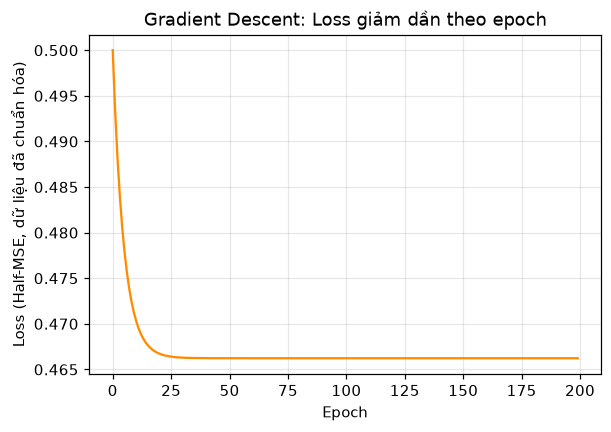

In [13]:
x_raw = X_train["Năm sản xuất"].to_numpy(dtype=float)
y_raw = y_train.to_numpy(dtype=float)

x_mean, x_std = x_raw.mean(), x_raw.std()
y_mean, y_std = y_raw.mean(), y_raw.std()

x_scaled = (x_raw - x_mean) / x_std
y_scaled = (y_raw - y_mean) / y_std

n = len(x_scaled)
w, b = 0.0, 0.0
learning_rate = 0.1
n_epochs = 200
loss_history = []

for epoch in range(n_epochs):
    y_hat = w * x_scaled + b
    error = y_hat - y_scaled

    loss = np.mean(error ** 2) / 2
    loss_history.append(loss)

    dL_dw = np.mean(error * x_scaled)
    dL_db = np.mean(error)

    w -= learning_rate * dL_dw
    b -= learning_rate * dL_db

print(f"Sau {n_epochs} epoch bằng Gradient Descent tự viết: w = {w:.4f}, b = {b:.4f}")

reference_model = LinearRegression()
reference_model.fit(x_scaled.reshape(-1, 1), y_scaled)
print(f"Đối chiếu với LinearRegression (cùng dữ liệu chuẩn hóa): "
      f"w = {reference_model.coef_[0]:.4f}, b = {reference_model.intercept_:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(loss_history, color="darkorange")
plt.title("Gradient Descent: Loss giảm dần theo epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss (Half-MSE, dữ liệu đã chuẩn hóa)")
plt.grid(alpha=0.3)
plt.show()

## 9. Mô hình hồi quy tuyến tính đa biến

Năm sản xuất không thể phản ánh đầy đủ sự khác biệt về giá giữa các xe. Hai xe được sản xuất trong cùng một năm vẫn có thể có mức giá chênh lệch đáng kể do khác hãng, kiểu dáng, xuất xứ, dung tích động cơ hoặc mức độ sử dụng. Vì vậy, mô hình thứ hai sử dụng toàn bộ bảy đặc trưng, gồm bốn đặc trưng số và ba đặc trưng phân loại.

Dữ liệu được tiền xử lý trước khi đưa vào `LinearRegression`:

- **Đặc trưng số — `StandardScaler`:** chuyển mỗi biến về thang đo có trung bình 0 và độ lệch chuẩn 1. Đối với hồi quy tuyến tính không có thành phần điều chuẩn, phép biến đổi này không làm thay đổi chất lượng khớp của mô hình, nhưng giúp cải thiện điều kiện số và hỗ trợ so sánh độ lớn của các hệ số số;
- **Đặc trưng phân loại — `OneHotEncoder`:** chuyển mỗi mức phân loại thành một biến nhị phân. Ví dụ, `Hang_xe` được mở rộng thành các cột như `Hang_xe_Toyota` và `Hang_xe_Kia`. Tham số `handle_unknown="ignore"` cho phép pipeline xử lý các mức phân loại chưa xuất hiện trong tập huấn luyện mà không phát sinh lỗi.

Hai thành phần của `scikit-learn` được sử dụng để tổ chức quy trình:

- `ColumnTransformer` áp dụng phép biến đổi tương ứng cho từng nhóm đặc trưng;
- `Pipeline` liên kết bước tiền xử lý và mô hình thành một quy trình thống nhất. Khi gọi `fit()` trên tập huấn luyện, các tham số tiền xử lý chỉ được ước lượng từ tập này. Khi gọi `predict()` trên tập kiểm tra, pipeline chỉ áp dụng lại các phép biến đổi đã học, qua đó hạn chế nguy cơ rò rỉ dữ liệu.

In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        ("so", StandardScaler(), numeric_cols),
        ("hang_muc", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ]
)

multi_model = Pipeline(steps=[
    ("tien_xu_ly", preprocessor),
    ("hoi_quy", LinearRegression()),
])

multi_model.fit(X_train, y_train)
y_pred_multi = multi_model.predict(X_test)

res_multi = evaluate("2. Linear Regression nhiều biến", y_test, y_pred_multi)
results.append(res_multi)
predictions["2. Linear Regression nhiều biến"] = y_pred_multi

[2. Linear Regression nhiều biến] MAE = 392.01 | RMSE = 668.16 | R2 = 0.6598


## 10. Mô hình hồi quy trên biến đổi logarit của giá

Kết quả EDA cho thấy phân phối giá xe lệch phải: phần lớn quan sát tập trung ở vùng giá thấp và trung bình, trong khi một số ít xe có giá rất cao. Các quan sát ở vùng giá cao có thể tạo ra sai số bình phương lớn và chi phối quá trình ước lượng.

Để giảm mức độ bất đối xứng của phân phối và hạn chế ảnh hưởng tương đối của các giá trị lớn, biến mục tiêu được biến đổi bằng hàm logarit:

$$y_{\log}=\log(1+\text{Giá})$$

Phép biến đổi logarit làm giảm khoảng cách tương đối giữa các giá trị lớn. Mô hình vì vậy tối ưu sai số trên thang logarit, tương ứng với việc chú trọng hơn đến sai số theo tỷ lệ thay vì chỉ sai số tuyệt đối trên thang giá gốc.

Quy trình thực hiện gồm:

1. chuyển giá của tập huấn luyện sang thang logarit bằng `np.log1p`, tương ứng với $\log(1+x)$;
2. huấn luyện pipeline có cấu trúc tương tự mô hình đa biến trên biến mục tiêu đã biến đổi;
3. chuyển dự đoán về đơn vị triệu VNĐ bằng `np.expm1` trước khi tính các chỉ số MAE, RMSE và $R^2$.

Cần lưu ý rằng phép biến đổi ngược trực tiếp có thể tạo ra sai lệch khi ước lượng kỳ vọng trên thang giá gốc. Trong phạm vi notebook, cách tiếp cận này được sử dụng để so sánh thực nghiệm; một nghiên cứu chuyên sâu hơn có thể xem xét hiệu chỉnh sai lệch khi biến đổi ngược.

In [15]:
log_model = Pipeline(steps=[
    ("tien_xu_ly", ColumnTransformer(
        transformers=[
            ("so", StandardScaler(), numeric_cols),
            ("hang_muc", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ]
    )),
    ("hoi_quy", LinearRegression()),
])

y_train_log = np.log1p(y_train)
log_model.fit(X_train, y_train_log)

y_pred_log = log_model.predict(X_test)
y_pred_log_million = np.expm1(y_pred_log)

res_log = evaluate("3. Linear Regression trên log(giá)", y_test, y_pred_log_million)
results.append(res_log)
predictions["3. Linear Regression trên log(giá)"] = y_pred_log_million

[3. Linear Regression trên log(giá)] MAE = 242.81 | RMSE = 532.47 | R2 = 0.7839


## 11. Phân tích các hệ số hồi quy

Một ưu điểm của hồi quy tuyến tính là khả năng diễn giải thông qua các tham số của mô hình. Các hệ số hồi quy được lưu trong thuộc tính `coef_`, còn hệ số chặn được lưu trong `intercept_`.

Phần này khảo sát hệ số của mô hình đa biến vì biến mục tiêu vẫn được biểu diễn trực tiếp theo đơn vị triệu VNĐ:

- **đặc trưng số:** sau khi được chuẩn hóa bằng `StandardScaler`, một hệ số biểu thị mức thay đổi của giá dự đoán khi đặc trưng tương ứng tăng một độ lệch chuẩn, trong điều kiện các đặc trưng còn lại không đổi;
- **đặc trưng phân loại:** mỗi hệ số gắn với một biến nhị phân do `OneHotEncoder` tạo ra. Tuy nhiên, cấu hình hiện tại giữ lại toàn bộ mức phân loại đồng thời sử dụng hệ số chặn, dẫn đến quan hệ phụ thuộc tuyến tính giữa các biến giả. `LinearRegression` vẫn có thể tính một nghiệm số, nhưng từng hệ số phân loại không có cách diễn giải duy nhất như mức chênh lệch so với một nhóm tham chiếu. Do đó, bảng hệ số hãng xe chỉ nên được sử dụng để khảo sát sơ bộ, không nên xem là kết luận độc lập.

Ngoài ra, hệ số hồi quy phản ánh **mối liên hệ có điều kiện** trong tập dữ liệu quan sát, không chứng minh quan hệ nhân quả. Hiện tượng đa cộng tuyến giữa các đặc trưng, chẳng hạn giữa năm sản xuất và số kilômét đã đi, có thể làm hệ số thay đổi mạnh hoặc mang dấu trái với kỳ vọng trực giác. Muốn diễn giải chặt chẽ hơn, cần kiểm tra đa cộng tuyến, lựa chọn một mức tham chiếu cho biến phân loại và ước lượng khoảng tin cậy của các hệ số.

In [16]:
feature_names = multi_model.named_steps["tien_xu_ly"].get_feature_names_out()
coefficients = multi_model.named_steps["hoi_quy"].coef_

coef_df = pd.DataFrame({"Đặc trưng": feature_names, "Hệ số": coefficients})
coef_df["Đặc trưng"] = coef_df["Đặc trưng"].str.replace("so__", "", regex=False).str.replace("hang_muc__", "", regex=False)

print(f"Intercept (b): {multi_model.named_steps['hoi_quy'].intercept_:,.2f}")
print("\nHệ số của các cột số (đơn vị: triệu VNĐ / 1 độ lệch chuẩn):")
print(coef_df[coef_df["Đặc trưng"].isin(numeric_cols)].to_string(index=False))

hang_xe_coef = coef_df[coef_df["Đặc trưng"].str.startswith("Hang_xe_")].sort_values("Hệ số")
print("\n5 hãng xe có hệ số thấp nhất:")
print(hang_xe_coef.head(5).to_string(index=False))
print("\n5 hãng xe có hệ số cao nhất:")
print(hang_xe_coef.tail(5).to_string(index=False))

Intercept (b): 1,420.77

Hệ số của các cột số (đơn vị: triệu VNĐ / 1 độ lệch chuẩn):
        Đặc trưng      Hệ số
     Năm sản xuất 456.956702
            So_km  13.408062
Dung_tich_dong_co 473.403779
      So_cho_ngoi -39.700512

5 hãng xe có hệ số thấp nhất:
      Đặc trưng        Hệ số
    Hang_xe_Gaz -2031.791536
Hang_xe_Dongben -1448.583763
  Hang_xe_Zotye -1199.792352
   Hang_xe_Baic -1133.336952
  Hang_xe_Acura -1110.263190

5 hãng xe có hệ số cao nhất:
      Đặc trưng       Hệ số
Hang_xe_Bentley 1313.112996
  Hang_xe_Rolls 2682.729831
Hang_xe_Lincoln 3331.276923
Hang_xe_Maybach 4941.766373
Hang_xe_Ferrari 5416.089637


## 12. So sánh mô hình và phân tích phần dư

Kết quả của ba mô hình được tổng hợp trong cùng một bảng và sắp xếp theo $R^2$ trên tập kiểm tra. Trong phạm vi thực nghiệm này, mô hình có MAE và RMSE thấp hơn đồng thời đạt $R^2$ cao hơn được xem là mô hình có hiệu năng tốt hơn. Việc lựa chọn cuối cùng vẫn cần cân nhắc mục tiêu sử dụng, mức sai số chấp nhận được và tính ổn định trên nhiều lần phân chia dữ liệu.

Hai biểu đồ chẩn đoán được xây dựng cho mô hình đạt kết quả tốt nhất:

- **Giá thực tế so với giá dự đoán:** mỗi điểm biểu diễn một quan sát trong tập kiểm tra. Đường chéo màu đen thể hiện trường hợp dự đoán hoàn toàn trùng khớp với giá thực tế; các điểm càng gần đường này thì sai số dự đoán càng nhỏ;
- **Biểu đồ phần dư:** phần dư được xác định bằng giá thực tế trừ giá dự đoán. Biểu đồ này hỗ trợ khảo sát hai giả định quan trọng:
  - phần dư nên phân bố ngẫu nhiên quanh đường 0; cấu trúc cong hoặc xu hướng có hệ thống có thể cho thấy quan hệ tuyến tính chưa mô tả đầy đủ dữ liệu;
  - độ phân tán của phần dư nên tương đối ổn định trên miền dự đoán. Dạng phân tán mở rộng dần ở vùng giá cao là dấu hiệu của phương sai sai số không đồng nhất (heteroscedasticity).

Các biểu đồ trên có vai trò chẩn đoán chứ không phải kiểm định thống kê chính thức. Việc đánh giá đầy đủ hơn có thể bổ sung biểu đồ Q–Q, kiểm định phương sai thay đổi và phân tích các quan sát có ảnh hưởng lớn.

In [17]:
comparison_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
comparison_df

,Mô hình,MAE,RMSE,R2
0,3. Linear Regression trên log(giá),242.810054,532.472990,0.783923
1,2. Linear Regression nhiều biến,392.011243,668.163639,0.659765
2,1. Baseline (1 biến),680.069495,1113.094364,0.055770


Mô hình tốt nhất theo R2 trên tập Test: 3. Linear Regression trên log(giá)


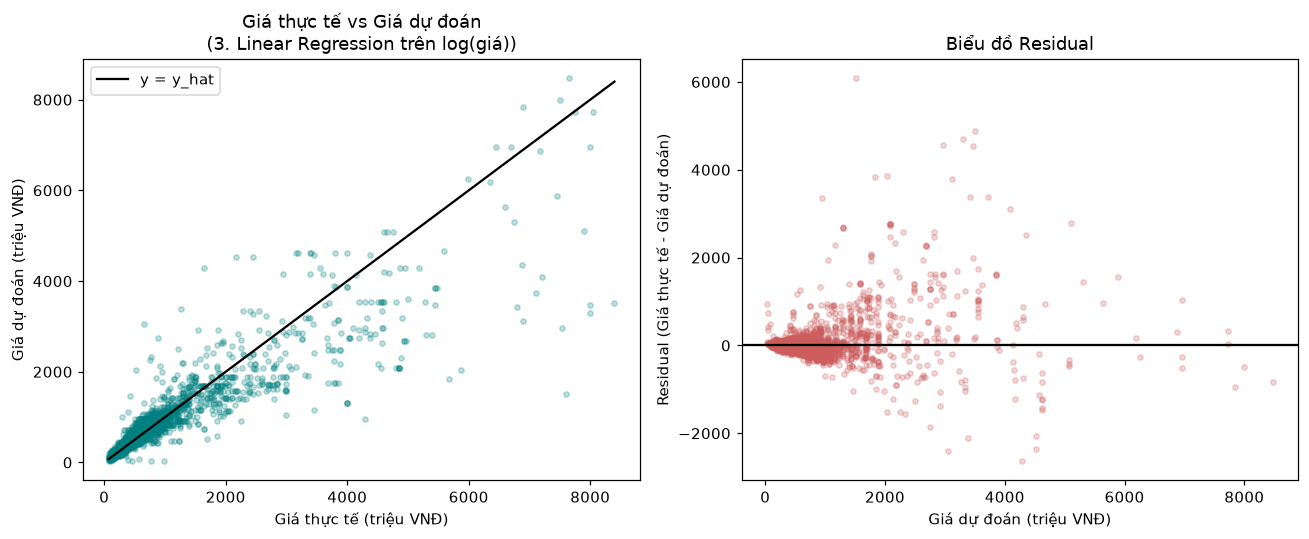

In [18]:
best_name = comparison_df.iloc[0]["Mô hình"]
best_pred = predictions[best_name]
print(f"Mô hình tốt nhất theo R2 trên tập Test: {best_name}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, best_pred, alpha=0.25, s=12, color="teal")
min_v, max_v = y_test.min(), y_test.max()
axes[0].plot([min_v, max_v], [min_v, max_v], color="black", linewidth=1.5, label="y = y_hat")
axes[0].set_xlabel("Giá thực tế (triệu VNĐ)")
axes[0].set_ylabel("Giá dự đoán (triệu VNĐ)")
axes[0].set_title(f"Giá thực tế vs Giá dự đoán\n({best_name})")
axes[0].legend()

residuals = y_test.to_numpy() - best_pred
axes[1].scatter(best_pred, residuals, alpha=0.25, s=12, color="indianred")
axes[1].axhline(0, color="black", linewidth=1.5)
axes[1].set_xlabel("Giá dự đoán (triệu VNĐ)")
axes[1].set_ylabel("Residual (Giá thực tế - Giá dự đoán)")
axes[1].set_title("Biểu đồ Residual")

fig.tight_layout()
plt.show()

## 13. Minh họa dự đoán trên một quan sát mới

Phần này sử dụng mô hình đạt kết quả tốt nhất trên tập kiểm tra để ước lượng giá cho một xe giả định có các thuộc tính: hãng Toyota, kiểu dáng SUV, sản xuất năm 2020, đã di chuyển 40.000 km, dung tích động cơ 2,0 lít, 7 chỗ ngồi và được lắp ráp trong nước.

Dữ liệu đầu vào được tổ chức dưới dạng một `DataFrame` có tên và thứ tự logic của các cột phù hợp với dữ liệu huấn luyện. Nhờ sử dụng `Pipeline`, các bước chuẩn hóa đặc trưng số và mã hóa one-hot cho đặc trưng phân loại được thực hiện tự động trước khi mô hình tạo dự đoán.

Kết quả thu được chỉ là giá trị ước lượng dựa trên các thuộc tính hiện có và phân phối của tập dữ liệu huấn luyện; kết quả không thay thế cho hoạt động thẩm định giá chuyên nghiệp.

In [19]:
sample_car = pd.DataFrame([{
    "Năm sản xuất": 2020,
    "So_km": 40000,
    "Dung_tich_dong_co": 2.0,
    "So_cho_ngoi": 7,
    "Xuất xứ": "Lắp ráp trong nước",
    "Kiểu dáng": "SUV",
    "Hang_xe": "Toyota",
}])

if best_name.startswith("1."):
    predicted_price = baseline_model.predict(sample_car[["Năm sản xuất"]])[0]
elif best_name.startswith("3."):
    predicted_price = np.expm1(log_model.predict(sample_car))[0]
else:
    predicted_price = multi_model.predict(sample_car)[0]

print(f"Mô hình sử dụng: {best_name}")
print("Thông tin xe cần dự đoán:")
print(sample_car.to_string(index=False))
print(f"\nGiá dự đoán: {predicted_price:,.0f} triệu VNĐ")

Mô hình sử dụng: 3. Linear Regression trên log(giá)
Thông tin xe cần dự đoán:
 Năm sản xuất  So_km  Dung_tich_dong_co  So_cho_ngoi            Xuất xứ Kiểu dáng Hang_xe
         2020  40000                2.0            7 Lắp ráp trong nước       SUV  Toyota

Giá dự đoán: 763 triệu VNĐ


## 14. Xây dựng giao diện minh họa bằng Gradio

`Gradio` là thư viện hỗ trợ xây dựng nhanh giao diện tương tác từ một hàm Python. Trong notebook, giao diện có thể được hiển thị trực tiếp bên dưới ô mã mà không cần tạo một tệp ứng dụng độc lập.

Nếu môi trường chưa cài đặt Gradio, có thể thực hiện lệnh sau trong Terminal:

```bash
pip install gradio
```

Ô mã tiếp theo thực hiện bốn nhiệm vụ:

1. lựa chọn giữa mô hình đa biến trên thang giá gốc và mô hình trên thang logarit dựa trên $R^2$ đã tính ở tập kiểm tra;
2. định nghĩa hàm `du_doan_gia()`, tiếp nhận bảy thuộc tính của xe, tạo một `DataFrame` gồm một quan sát và gọi mô hình để ước lượng giá;
3. xây dựng các thành phần giao diện:
   - `Slider` cho năm sản xuất;
   - `Number` cho số kilômét đã đi, dung tích động cơ và số chỗ ngồi;
   - `Dropdown` cho hãng xe, kiểu dáng và xuất xứ;
   - `Markdown` để hiển thị kết quả;
4. gọi `demo.launch(inline=True)` để khởi chạy giao diện trong notebook.

Người dùng có thể thay đổi các thuộc tính đầu vào và chọn **Dự đoán giá**, hoặc sử dụng các ví dụ có sẵn để kiểm tra nhanh. Giao diện này phục vụ mục đích minh họa quy trình triển khai mô hình, chưa phải một hệ thống định giá hoàn chỉnh.

In [20]:
import gradio as gr

# App dùng mô hình nhiều biến tốt hơn giữa Mô hình 2 và Mô hình 3.
if best_name.startswith("3."):
    app_model = log_model
    app_dung_log = True
else:
    app_model = multi_model
    app_dung_log = False

app_model_name = best_name
app_mae = comparison_df.set_index("Mô hình").loc[app_model_name, "MAE"]

# Lấy khoảng giá trị / danh sách lựa chọn từ dữ liệu để các ô nhập hợp lý.
khoang = {
    col: {
        "min": float(df_model[col].min()),
        "max": float(df_model[col].max()),
        "giua": float(df_model[col].median()),
    }
    for col in numeric_cols
}
lua_chon = {col: sorted(df_model[col].unique().tolist()) for col in categorical_cols}


def mac_dinh(value, col):
    """Giữ giá trị mặc định nằm trong khoảng dữ liệu mô hình đã học."""
    return min(max(value, khoang[col]["min"]), khoang[col]["max"])


def du_doan_gia(nam_san_xuat, so_km, dung_tich, so_cho, hang_xe, kieu_dang, xuat_xu):
    """Nhận thông tin từ giao diện, rồi trả về câu kết quả để Gradio hiển thị."""
    xe = pd.DataFrame([{
        "Năm sản xuất": nam_san_xuat,
        "So_km": so_km,
        "Dung_tich_dong_co": dung_tich,
        "So_cho_ngoi": so_cho,
        "Xuất xứ": xuat_xu,
        "Kiểu dáng": kieu_dang,
        "Hang_xe": hang_xe,
    }])

    gia_du_doan = app_model.predict(xe)[0]
    if app_dung_log:
        # Mô hình 3 dự đoán log(giá), nên cần đổi ngược lại thành triệu VNĐ.
        gia_du_doan = np.expm1(gia_du_doan)

    return (
        f"## Giá dự đoán: khoảng {gia_du_doan:,.0f} triệu VNĐ\n\n"
        f"Đây là con số ước lượng. Trên tập Test, mô hình trung bình lệch "
        f"khoảng **{app_mae:,.0f} triệu VNĐ** so với giá thật."
    )


# Mỗi danh sách bên dưới tương ứng với đúng thứ tự tham số của du_doan_gia().
inputs = [
    gr.Slider(
        minimum=int(khoang["Năm sản xuất"]["min"]),
        maximum=int(khoang["Năm sản xuất"]["max"]),
        value=int(mac_dinh(2020, "Năm sản xuất")),
        step=1,
        label="Năm sản xuất",
    ),
    gr.Number(
        minimum=0,
        maximum=int(khoang["So_km"]["max"]),
        value=int(mac_dinh(40000, "So_km")),
        label="Số km đã đi",
    ),
    gr.Number(
        minimum=khoang["Dung_tich_dong_co"]["min"],
        maximum=khoang["Dung_tich_dong_co"]["max"],
        value=mac_dinh(2.0, "Dung_tich_dong_co"),
        label="Dung tích động cơ (lít)",
    ),
    gr.Number(
        minimum=int(khoang["So_cho_ngoi"]["min"]),
        maximum=int(khoang["So_cho_ngoi"]["max"]),
        value=int(mac_dinh(5, "So_cho_ngoi")),
        label="Số chỗ ngồi",
    ),
    gr.Dropdown(lua_chon["Hang_xe"], value="Toyota", label="Hãng xe"),
    gr.Dropdown(lua_chon["Kiểu dáng"], value="SUV", label="Kiểu dáng"),
    gr.Dropdown(lua_chon["Xuất xứ"], value="Lắp ráp trong nước", label="Xuất xứ"),
]

examples = [
    [2020, 40000, 2.0, 7, "Toyota", "SUV", "Lắp ráp trong nước"],
    [2018, 60000, 1.5, 5, "Honda", "Sedan", "Lắp ráp trong nước"],
]

demo = gr.Interface(
    fn=du_doan_gia,
    inputs=inputs,
    outputs=gr.Markdown(label="Kết quả"),
    examples=examples,
    title="Dự đoán giá xe cũ bằng Linear Regression",
    description=(
        f"Đang dùng **{app_model_name}**. Nhập thông tin xe rồi bấm "
        "**Dự đoán giá** để xem kết quả."
    ),
    article=(
        "Lưu ý: giá dự đoán là ước lượng từ dữ liệu rao bán; không phải giá giao dịch chắc chắn."
    ),
    submit_btn="Dự đoán giá",
    clear_btn="Nhập lại",
    flagging_mode="never",
)

# inline=True: giao diện xuất hiện ngay dưới cell trong Jupyter / VS Code Notebook.
# prevent_thread_lock=True: cell chạy xong nhưng giao diện vẫn hoạt động.
demo.launch(inline=True, share=False, prevent_thread_lock=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## 15. Kết luận và định hướng phát triển

### Kết quả đạt được

Notebook đã xây dựng một quy trình tương đối đầy đủ cho bài toán ước lượng giá xe đã qua sử dụng:

- dữ liệu được khảo sát, làm sạch và chuyển đổi sang định dạng phù hợp với mô hình;
- hiệu năng được đánh giá trên tập kiểm tra độc lập thay vì trên dữ liệu huấn luyện;
- mô hình cơ sở chỉ sử dụng năm sản xuất được đối chiếu với mô hình đa biến sử dụng bảy đặc trưng;
- phép biến đổi logarit của giá giúp cải thiện các chỉ số MAE, RMSE và $R^2$ trong lần phân chia dữ liệu hiện tại;
- thuật toán Gradient Descent được cài đặt để minh họa quá trình tối ưu tham số;
- các hệ số hồi quy và biểu đồ phần dư được khảo sát nhằm hỗ trợ diễn giải mô hình;
- giao diện Gradio được tích hợp để minh họa cách đưa mô hình vào một ứng dụng tương tác.

### Hạn chế của nghiên cứu

- Phương pháp trích xuất hãng xe chỉ sử dụng từ đầu tiên trong tên xe nên có thể phân loại chưa chính xác đối với các hãng có tên gồm nhiều từ, chẳng hạn `Mercedes Benz`;
- việc loại bỏ toàn bộ quan sát thiếu dữ liệu có thể làm giảm kích thước mẫu và tạo sai lệch nếu dữ liệu không thiếu hoàn toàn ngẫu nhiên;
- ngưỡng loại bỏ 1% ở hai đầu phân phối giá mang tính thực nghiệm và chưa được đối chiếu với tiêu chí nghiệp vụ;
- mô hình hồi quy tuyến tính giả định quan hệ tuyến tính và phương sai sai số tương đối ổn định, trong khi biểu đồ phần dư cho thấy sai số có xu hướng lớn hơn ở vùng giá cao;
- dữ liệu tin đăng phản ánh giá chào bán tại một thời điểm, không nhất thiết là giá giao dịch thực tế và chưa mô hình hóa biến động thị trường theo thời gian;
- kết quả hiện tại dựa trên một lần chia Train/Test, do đó chưa đủ để khẳng định độ ổn định của mô hình trên các mẫu dữ liệu khác.

### Định hướng phát triển

- chuẩn hóa tên hãng bằng từ điển thương hiệu và quy tắc xử lý chuỗi chặt chẽ hơn;
- bổ sung các đặc trưng như loại nhiên liệu, hộp số, địa điểm, tình trạng xe và tuổi xe;
- xây dựng quy trình xử lý giá trị thiếu thay cho việc loại bỏ toàn bộ quan sát;
- áp dụng kiểm định chéo bằng `cross_val_score` hoặc `KFold` để đánh giá độ ổn định của MAE, RMSE và $R^2$;
- sử dụng `PolynomialFeatures`, biến đổi đặc trưng hoặc mô hình có thành phần điều chuẩn như Ridge và Lasso để xử lý quan hệ phi tuyến nhẹ và đa cộng tuyến;
- đánh giá mô hình trên dữ liệu thu thập ở thời điểm khác trước khi triển khai thực tế;
- lưu toàn bộ pipeline đã huấn luyện và xây dựng cơ chế kiểm tra dữ liệu đầu vào cho ứng dụng dự đoán.